Saving customer_churn.csv to customer_churn.csv
Data loaded: 500 rows and 9 columns

  CustomerID  Tenure  MonthlyCharges  TotalCharges        Contract  \
0     C00001       6              64          1540        One year   
1     C00002      21             113          1753  Month-to-month   
2     C00003      27              31          1455        Two year   
3     C00004      53              29          7150  Month-to-month   
4     C00005      16             185          1023        One year   

      PaymentMethod PaperlessBilling  SeniorCitizen  Churn  
0       Credit Card               No              1      0  
1  Electronic Check              Yes              1      0  
2       Credit Card               No              1      0  
3  Electronic Check               No              1      0  
4  Electronic Check               No              1      0  

DAY 1: DATA TYPES AND QUALITY
CustomerID          object
Tenure               int64
MonthlyCharges       int64
TotalCharges    

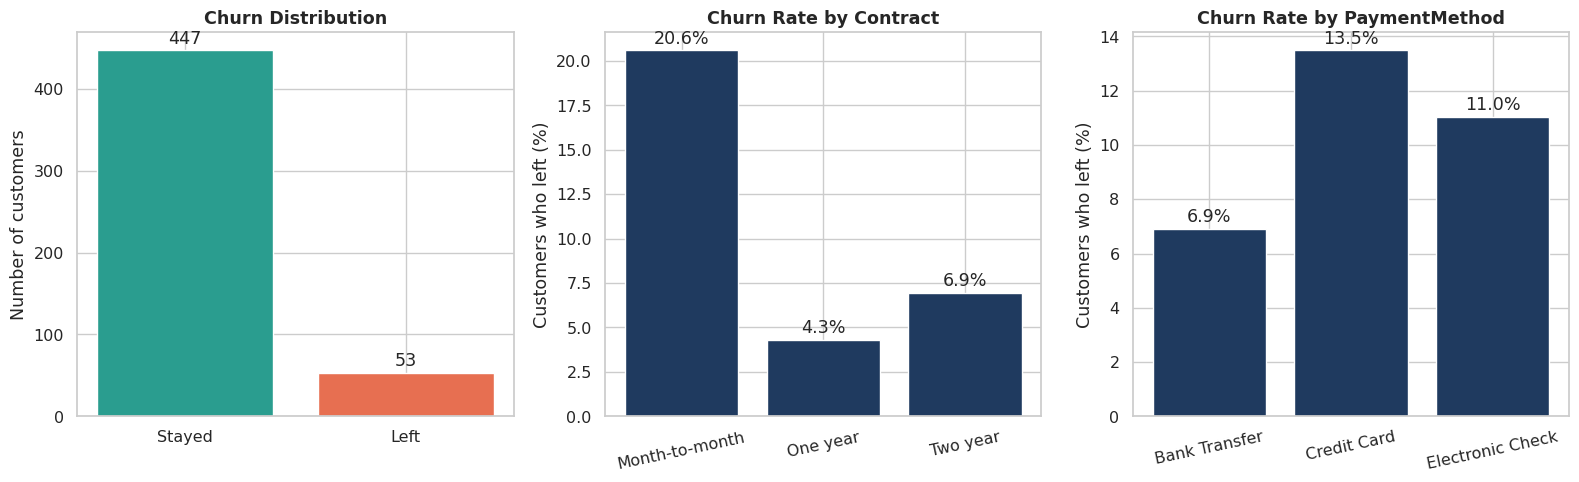

DAY 2: ENCODING CATEGORICAL VARIABLES
1. Label encoding of PaymentMethod:
   {'Bank Transfer': 0, 'Credit Card': 1, 'Electronic Check': 2}
   PaymentMethod has no real order, so label encoding is only shown for comparison.

2. Ordinal encoding of Contract (a longer contract = a bigger number):
   Month-to-month = 0, One year = 1, Two year = 2

3. One-hot encoding of PaymentMethod creates these columns: ['Payment_Bank Transfer', 'Payment_Credit Card', 'Payment_Electronic Check']

4. Binary encoding of PaperlessBilling: Yes = 1, No = 0
5. Frequency encoding of PaymentMethod (share of customers using each method):
    {'Credit Card': 0.356, 'Electronic Check': 0.326, 'Bank Transfer': 0.318}

Result (first 6 rows, original and encoded columns side by side):
         Contract  Contract_ordinal     PaymentMethod  PaymentMethod_label  Payment_Bank Transfer  Payment_Credit Card  Payment_Electronic Check  PaymentMethod_freq PaperlessBilling  PaperlessBilling_binary
0        One year            

In [ ]:

# Week 10: Data Preprocessing and Feature Engineering - Customer Churn Prediction
# Part 1: Explore the data (Day 1) and encode categorical variables (Day 2)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

sns.set_theme(style='whitegrid', font_scale=1.05)
os.makedirs('figures', exist_ok=True)
TEAL, ORANGE, NAVY, GREY = '#2a9d8f', '#e76f51', '#1f3a5f', '#9aa5b1'

# ---------- Load the data (upload customer_churn.csv) ----------
uploaded = files.upload()
file_name = None
for name in uploaded:
    if 'churn' in name.lower() or 'customer' in name.lower():
        file_name = name

if file_name is None:
    print("Error: please upload the customer churn file (customer_churn.csv).")
else:
    df = pd.read_csv(file_name)
    df.to_csv('churn_data.csv', index=False)          # the data file for submission
    print("Data loaded:", df.shape[0], "rows and", df.shape[1], "columns")
    print()
    print(df.head())

    # =================================================================
    # DAY 1: EXPLORE AND UNDERSTAND
    # =================================================================
    print()
    print("=" * 60)
    print("DAY 1: DATA TYPES AND QUALITY")
    print("=" * 60)
    print(df.dtypes.astype(str).to_string())
    print()
    print("Missing values:", int(df.isnull().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))
    print("Duplicate customer IDs:", int(df['CustomerID'].duplicated().sum()))
    print()
    print(df.describe().round(1).to_string())

    print()
    print("Churn distribution:")
    counts = df['Churn'].value_counts().sort_index()
    print(f"  Stayed (0): {counts[0]} ({counts[0] / len(df) * 100:.1f}%)")
    print(f"  Left   (1): {counts[1]} ({counts[1] / len(df) * 100:.1f}%)")
    print("  The data is imbalanced: far fewer customers left than stayed.")

    print()
    print("Churn rate for each category:")
    for col in ['Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']:
        rates = (df.groupby(col)['Churn'].mean() * 100).round(1)
        print(f"  {col}: " + ", ".join(f"{k} = {v}%" for k, v in rates.items()))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    axes[0].bar(['Stayed', 'Left'], [counts[0], counts[1]], color=[TEAL, ORANGE])
    axes[0].set_title('Churn Distribution', fontweight='bold')
    axes[0].set_ylabel('Number of customers')
    for i, v in enumerate([counts[0], counts[1]]):
        axes[0].annotate(str(v), (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')
    for ax, col in zip(axes[1:], ['Contract', 'PaymentMethod']):
        r = (df.groupby(col)['Churn'].mean() * 100).reset_index()
        ax.bar(r[col], r['Churn'], color=NAVY)
        ax.set_title(f'Churn Rate by {col}', fontweight='bold')
        ax.set_ylabel('Customers who left (%)')
        for i, v in enumerate(r['Churn']):
            ax.annotate(f"{v:.1f}%", (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')
        ax.tick_params(axis='x', rotation=12)
    plt.tight_layout()
    plt.savefig('figures/1_churn_overview.png', dpi=150, bbox_inches='tight')
    plt.show()

    # =================================================================
    # DAY 2: HANDLE CATEGORICAL DATA (5 encoding methods)
    # =================================================================
    print("=" * 60)
    print("DAY 2: ENCODING CATEGORICAL VARIABLES")
    print("=" * 60)
    encoded = df.copy()

    # Method 1: LABEL ENCODING - each category gets a number (PaymentMethod)
    label_encoder = LabelEncoder()
    encoded['PaymentMethod_label'] = label_encoder.fit_transform(df['PaymentMethod'])
    print("1. Label encoding of PaymentMethod:")
    print("  ", {c: int(i) for i, c in enumerate(label_encoder.classes_)})
    print("   Warning: this makes 'Electronic Check' (2) look bigger than 'Bank Transfer' (0).")
    print("   PaymentMethod has no real order, so label encoding is only shown for comparison.")

    # Method 2: ORDINAL ENCODING - numbers that follow a real order (Contract)
    contract_order = [['Month-to-month', 'One year', 'Two year']]
    ordinal_encoder = OrdinalEncoder(categories=contract_order)
    encoded['Contract_ordinal'] = ordinal_encoder.fit_transform(df[['Contract']]).astype(int).ravel()
    print()
    print("2. Ordinal encoding of Contract (a longer contract = a bigger number):")
    print("   Month-to-month = 0, One year = 1, Two year = 2")

    # Method 3: ONE-HOT ENCODING - one 0/1 column per category (PaymentMethod)
    onehot = pd.get_dummies(df['PaymentMethod'], prefix='Payment', dtype=int)
    encoded = pd.concat([encoded, onehot], axis=1)
    print()
    print("3. One-hot encoding of PaymentMethod creates these columns:", list(onehot.columns))

    # Method 4 and 5: BINARY (YES/NO) ENCODING and FREQUENCY ENCODING
    encoded['PaperlessBilling_binary'] = (df['PaperlessBilling'] == 'Yes').astype(int)
    print()
    print("4. Binary encoding of PaperlessBilling: Yes = 1, No = 0")
    freq = df['PaymentMethod'].value_counts(normalize=True)
    encoded['PaymentMethod_freq'] = df['PaymentMethod'].map(freq).round(3)
    print("5. Frequency encoding of PaymentMethod (share of customers using each method):")
    print("   ", freq.round(3).to_dict())

    print()
    print("Result (first 6 rows, original and encoded columns side by side):")
    show = ['Contract', 'Contract_ordinal', 'PaymentMethod', 'PaymentMethod_label',
            'Payment_Bank Transfer', 'Payment_Credit Card', 'Payment_Electronic Check',
            'PaymentMethod_freq', 'PaperlessBilling', 'PaperlessBilling_binary']
    print(encoded[show].head(6).to_string())

    print()
    summary = pd.DataFrame([
        ['Label encoding', 'PaymentMethod', 'Numbers 0, 1, 2', 'Categories with no order, only for models that ignore order (such as trees)'],
        ['Ordinal encoding', 'Contract', 'Numbers that follow a real order', 'Categories that have a natural order'],
        ['One-hot encoding', 'PaymentMethod', 'One 0/1 column per category', 'Categories with no order and few values'],
        ['Binary encoding', 'PaperlessBilling', 'Yes = 1, No = 0', 'Two categories'],
        ['Frequency encoding', 'PaymentMethod', 'Share of customers in the category', 'Categories with many values']],
        columns=['Method', 'Column', 'What it does', 'When to use it'])
    print(summary.to_string(index=False))
    print()
    print("Columns now:", encoded.shape[1], "| CustomerID is only a label, so it is not used as a feature.")

TRAIN-TEST SPLIT
Training customers: 400 (churn rate 10.5%)
Testing customers:  100 (churn rate 11.0%)
stratify keeps the same churn rate in both parts.

DAY 3: SCALING COMPARISON (MonthlyCharges, training data)
                    Method    Min     Max    Mean    Std
                  Original 20.000 199.000 113.492 52.353
           Min-Max scaling  0.000   1.000   0.522  0.292
Standard scaling (z-score) -1.788   1.635  -0.000  1.001
            Robust scaling -1.038   0.918  -0.016  0.572

Checks:
  Min-Max: every training column goes from 0.0 to 1.0
  Standard: training mean is about 0.000 and std about 1.00
  Min-Max on TEST data: smallest 0.000, largest 1.000
  Here the test values stay inside 0 to 1. With other data they can fall outside,
  because the scaler only learned the minimum and maximum from the training data.

Which one to use?
  Min-Max: squeezes values into 0 to 1; good for neural networks and distance-based models; sensitive to outliers.
  Standard: centers at 0 wit

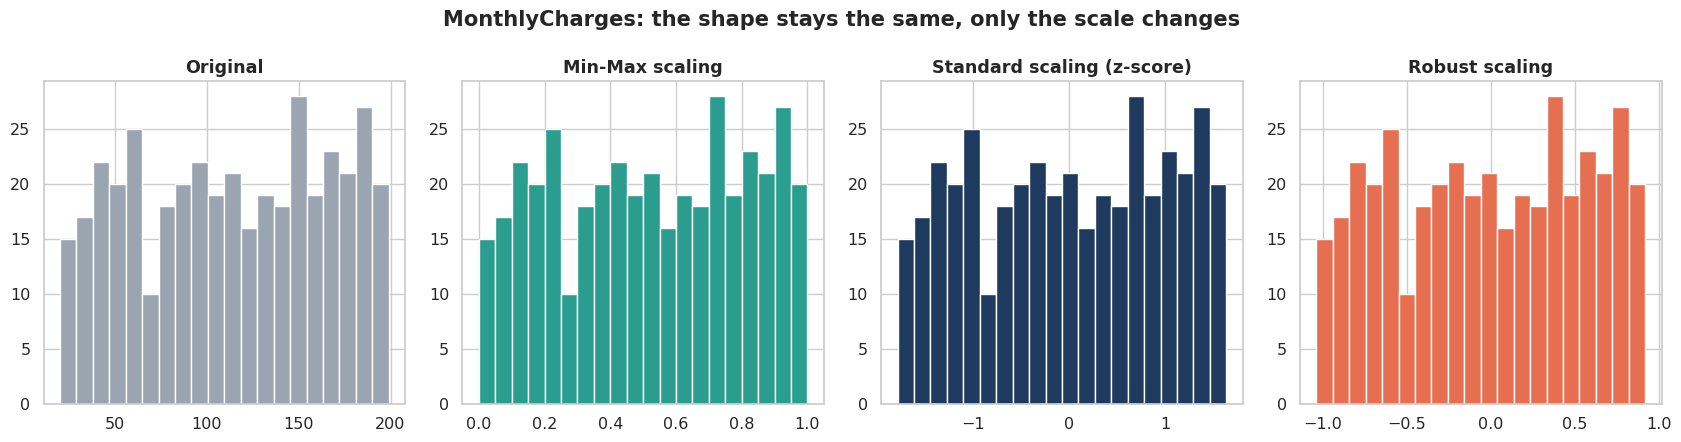

DAY 4: OUTLIERS IN THE REAL DATA
        Column  IQR outliers  Z-score outliers (above 3)
        Tenure             0                           0
MonthlyCharges             0                           0
  TotalCharges             0                           0

Finding: this data has no outliers, so nothing needs to be removed.
Removing real values without a reason would throw away information.


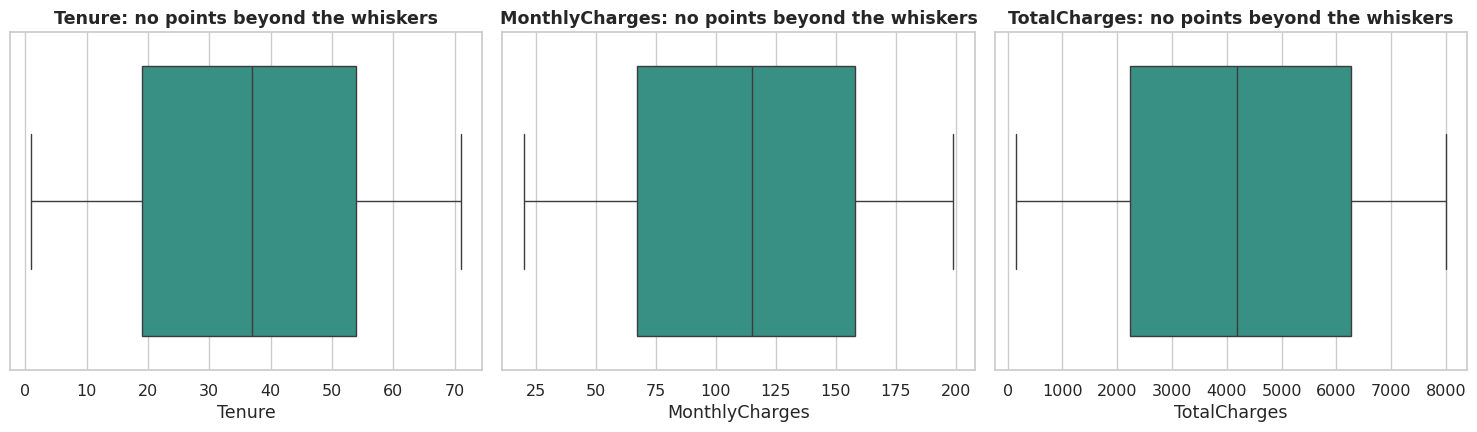

TEST: ADD TWO FAKE OUTLIERS AND SEE IF THE METHODS FIND THEM
IQR method found:     2 outliers (expected 2)
Z-score method found: 2 outliers (expected 2)
Capping at the IQR limits (-68 to 294): max value 1500 -> 294
Capping keeps the customer but limits the extreme value. Removing deletes the customer.

Capped columns added to the data: ['Tenure_capped', 'MonthlyCharges_capped', 'TotalCharges_capped']
Real values changed by capping: 0 (none, because there are no outliers)


In [ ]:
# Part 2: Feature scaling (Day 3) and outlier detection and handling (Day 4)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

num_cols = ['Tenure', 'MonthlyCharges', 'TotalCharges']

# =====================================================================
# DAY 3: FEATURE SCALING
# First split the data, then fit each scaler on the TRAINING customers only.
# (Fitting on all the data would leak information from the test set.)
# =====================================================================
train_df, test_df = train_test_split(encoded, test_size=0.2, random_state=42, stratify=encoded['Churn'])
print("=" * 60)
print("TRAIN-TEST SPLIT")
print("=" * 60)
print(f"Training customers: {len(train_df)} (churn rate {train_df['Churn'].mean() * 100:.1f}%)")
print(f"Testing customers:  {len(test_df)} (churn rate {test_df['Churn'].mean() * 100:.1f}%)")
print("stratify keeps the same churn rate in both parts.")

scalers = {'Min-Max scaling': MinMaxScaler(),
           'Standard scaling (z-score)': StandardScaler(),
           'Robust scaling': RobustScaler()}
scaled_train = {}
scaled_test = {}
for name, scaler in scalers.items():
    scaler.fit(train_df[num_cols])                                   # learn from training data only
    scaled_train[name] = pd.DataFrame(scaler.transform(train_df[num_cols]), columns=num_cols, index=train_df.index)
    scaled_test[name] = pd.DataFrame(scaler.transform(test_df[num_cols]), columns=num_cols, index=test_df.index)

print()
print("=" * 60)
print("DAY 3: SCALING COMPARISON (MonthlyCharges, training data)")
print("=" * 60)
rows = [['Original', train_df['MonthlyCharges'].min(), train_df['MonthlyCharges'].max(),
         train_df['MonthlyCharges'].mean(), train_df['MonthlyCharges'].std()]]
for name in scalers:
    s = scaled_train[name]['MonthlyCharges']
    rows.append([name, s.min(), s.max(), s.mean(), s.std()])
print(pd.DataFrame(rows, columns=['Method', 'Min', 'Max', 'Mean', 'Std']).round(3).to_string(index=False))

print()
print("Checks:")
mm = scaled_train['Min-Max scaling']
print(f"  Min-Max: every training column goes from {mm.min().min():.1f} to {mm.max().max():.1f}")
sd = scaled_train['Standard scaling (z-score)']
print(f"  Standard: training mean is about {sd.mean().abs().max():.3f} and std about {sd.std().mean():.2f}")
mt = scaled_test['Min-Max scaling']
print(f"  Min-Max on TEST data: smallest {mt.min().min():.3f}, largest {mt.max().max():.3f}")
if mt.min().min() >= 0 and mt.max().max() <= 1:
    print("  Here the test values stay inside 0 to 1. With other data they can fall outside,")
    print("  because the scaler only learned the minimum and maximum from the training data.")
else:
    print("  Some test values fall outside 0 to 1 because the scaler only learned from the training data.")

print()
print("Which one to use?")
print("  Min-Max: squeezes values into 0 to 1; good for neural networks and distance-based models; sensitive to outliers.")
print("  Standard: centers at 0 with std 1; good for logistic regression and SVM; the usual default.")
print("  Robust: uses the median and IQR; the best choice when there are outliers.")
print("  Tree models (Decision Tree, Random Forest) do not need scaling.")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
axes[0].hist(train_df['MonthlyCharges'], bins=20, color=GREY)
axes[0].set_title('Original', fontweight='bold')
for ax, (name, color) in zip(axes[1:], [('Min-Max scaling', TEAL), ('Standard scaling (z-score)', NAVY), ('Robust scaling', ORANGE)]):
    ax.hist(scaled_train[name]['MonthlyCharges'], bins=20, color=color)
    ax.set_title(name, fontweight='bold')
fig.suptitle('MonthlyCharges: the shape stays the same, only the scale changes', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/2_scaling_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# =====================================================================
# DAY 4: OUTLIER DETECTION AND HANDLING (IQR and Z-score)
# =====================================================================
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def iqr_outliers(series):
    low, high = iqr_bounds(series)
    return (series < low) | (series > high)

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return z.abs() > threshold

print("=" * 60)
print("DAY 4: OUTLIERS IN THE REAL DATA")
print("=" * 60)
outlier_rows = []
for col in num_cols:
    outlier_rows.append([col, int(iqr_outliers(encoded[col]).sum()), int(zscore_outliers(encoded[col]).sum())])
print(pd.DataFrame(outlier_rows, columns=['Column', 'IQR outliers', 'Z-score outliers (above 3)']).to_string(index=False))
print()
print("Finding: this data has no outliers, so nothing needs to be removed.")
print("Removing real values without a reason would throw away information.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=encoded[col], color=TEAL, ax=ax)
    ax.set_title(f'{col}: no points beyond the whiskers', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/3_outlier_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Testing evidence: do our detectors really work? ----------
print("=" * 60)
print("TEST: ADD TWO FAKE OUTLIERS AND SEE IF THE METHODS FIND THEM")
print("=" * 60)
test_series = encoded['MonthlyCharges'].copy()
test_series.iloc[0] = 1500          # fake outlier 1
test_series.iloc[1] = 900           # fake outlier 2
print("IQR method found:    ", int(iqr_outliers(test_series).sum()), "outliers (expected 2)")
print("Z-score method found:", int(zscore_outliers(test_series).sum()), "outliers (expected 2)")

low, high = iqr_bounds(test_series)
capped = test_series.clip(lower=low, upper=high)                  # capping (winsorizing)
print(f"Capping at the IQR limits ({low:.0f} to {high:.0f}): max value {test_series.max():.0f} -> {capped.max():.0f}")
print("Capping keeps the customer but limits the extreme value. Removing deletes the customer.")

# ---------- Capping as a ready-to-use pipeline step on the real data ----------
changed_total = 0
for col in num_cols:
    low, high = iqr_bounds(encoded[col])
    encoded[col + '_capped'] = encoded[col].clip(lower=low, upper=high)
    changed_total += int((encoded[col + '_capped'] != encoded[col]).sum())
print()
print("Capped columns added to the data:", [c + '_capped' for c in num_cols])
print("Real values changed by capping:", changed_total, "(none, because there are no outliers)")

DAY 5: NEW FEATURES (9 created, the task needs 5 or more)
         Feature                                         How it is made                                   Why it could matter
TenureGroup_code                      Tenure cut into 4 groups (0 to 3)      Customers behave differently at different stages
       FirstYear                       1 if Tenure is 11 months or less                    The first year is the risky period
    EstimatedCLV                                Tenure x MonthlyCharges             How much revenue the customer has brought
  IsMonthToMonth                    1 if the contract is month-to-month                      No commitment means an easy exit
       IsAutoPay 1 for Credit Card or Bank Transfer (assumed automatic)              Automatic payment may mean less friction
      HighCharge       1 if MonthlyCharges is above the training median               Expensive plans may push customers away
      Tenure_log                                        log(

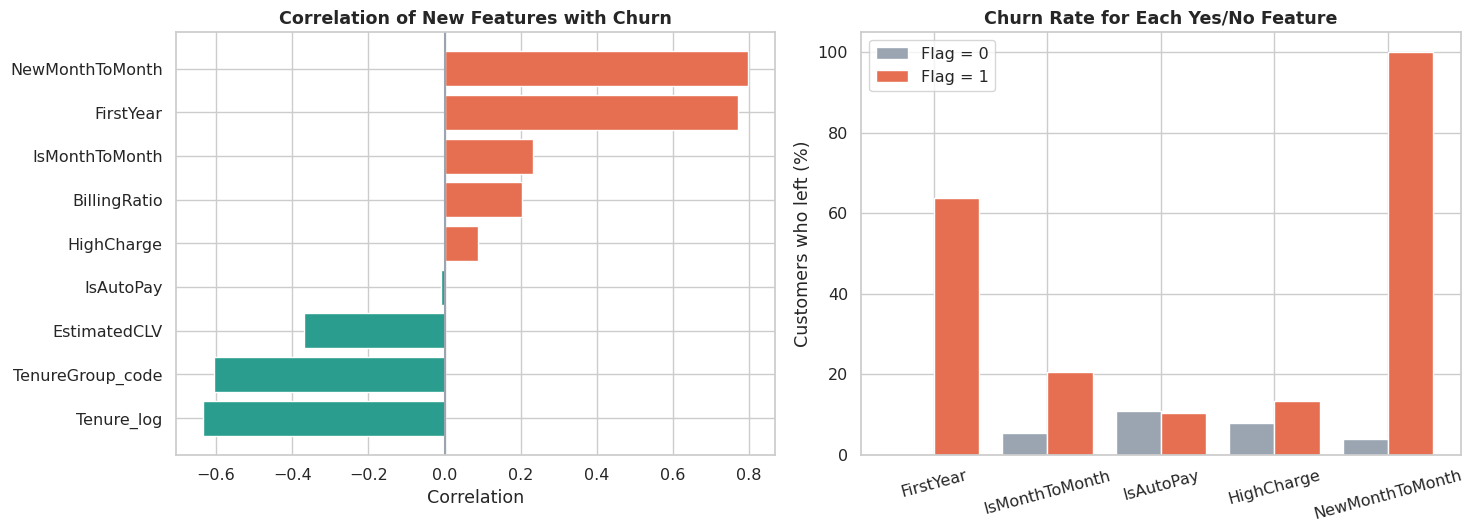

IMPORTANT WARNING ABOUT TENURE-BASED FEATURES
FirstYear, TenureGroup_code, Tenure_log, EstimatedCLV and NewMonthToMonth all come from Tenure.
The longest tenure of any customer who left is 11 months, so they look very strong.
But Tenure may be the time a customer stayed BEFORE leaving, which partly reveals the answer.
A model should not use information it would not have at prediction time. Part 5 tests the model both ways.


In [ ]:
# Part 3: Feature engineering (Day 5) - 9 new features

fe = encoded.copy()

# ---------- Create the new features ----------
fe['TenureGroup'] = pd.cut(fe['Tenure'], bins=[0, 11, 23, 47, 72],
                           labels=['0-11 months', '12-23 months', '24-47 months', '48+ months'])
fe['TenureGroup_code'] = fe['TenureGroup'].cat.codes                         # 0, 1, 2, 3
fe['FirstYear'] = (fe['Tenure'] <= 11).astype(int)
fe['EstimatedCLV'] = fe['Tenure'] * fe['MonthlyCharges']                     # customer lifetime value so far
fe['IsMonthToMonth'] = (fe['Contract'] == 'Month-to-month').astype(int)
fe['IsAutoPay'] = fe['PaymentMethod'].isin(['Credit Card', 'Bank Transfer']).astype(int)
fe['HighCharge'] = (fe['MonthlyCharges'] > train_df['MonthlyCharges'].median()).astype(int)   # median of TRAINING data
fe['Tenure_log'] = np.log1p(fe['Tenure'])
fe['NewMonthToMonth'] = fe['IsMonthToMonth'] * fe['FirstYear']
fe['BillingRatio'] = fe['TotalCharges'] / fe['EstimatedCLV']                 # payment efficiency

new_features = ['TenureGroup_code', 'FirstYear', 'EstimatedCLV', 'IsMonthToMonth', 'IsAutoPay',
                'HighCharge', 'Tenure_log', 'NewMonthToMonth', 'BillingRatio']

print("=" * 60)
print("DAY 5: NEW FEATURES (9 created, the task needs 5 or more)")
print("=" * 60)
doc = pd.DataFrame([
    ['TenureGroup_code', 'Tenure cut into 4 groups (0 to 3)', 'Customers behave differently at different stages'],
    ['FirstYear', '1 if Tenure is 11 months or less', 'The first year is the risky period'],
    ['EstimatedCLV', 'Tenure x MonthlyCharges', 'How much revenue the customer has brought'],
    ['IsMonthToMonth', '1 if the contract is month-to-month', 'No commitment means an easy exit'],
    ['IsAutoPay', '1 for Credit Card or Bank Transfer (assumed automatic)', 'Automatic payment may mean less friction'],
    ['HighCharge', '1 if MonthlyCharges is above the training median', 'Expensive plans may push customers away'],
    ['Tenure_log', 'log(1 + Tenure)', 'Reduces the effect of very long tenures'],
    ['NewMonthToMonth', 'IsMonthToMonth x FirstYear', 'New customers with no commitment'],
    ['BillingRatio', 'TotalCharges / EstimatedCLV', 'Checks if the billed total matches tenure and charges']],
    columns=['Feature', 'How it is made', 'Why it could matter'])
print(doc.to_string(index=False))

print()
print(fe[['Tenure', 'MonthlyCharges', 'Contract'] + new_features].head(6).round(2).to_string())

# ---------- Validate the new features ----------
print()
print("=" * 60)
print("VALIDATION: IS EACH NEW FEATURE LINKED TO CHURN?")
print("=" * 60)
corr = fe[new_features].corrwith(fe['Churn']).sort_values()
print("Correlation with Churn (0 = no link, 1 or -1 = strong link):")
print(corr.round(3).to_string())

flags = ['FirstYear', 'IsMonthToMonth', 'IsAutoPay', 'HighCharge', 'NewMonthToMonth']
print()
print("Churn rate when the flag is 0 and when it is 1:")
flag_rows = []
for f in flags:
    r = (fe.groupby(f)['Churn'].mean() * 100).round(1)
    flag_rows.append([f, r.get(0, np.nan), r.get(1, np.nan)])
    print(f"  {f}: 0 -> {r.get(0, np.nan)}%, 1 -> {r.get(1, np.nan)}%")

print()
print("BillingRatio (TotalCharges / EstimatedCLV):")
print(fe['BillingRatio'].describe().round(2).to_string())
print("A healthy billing record would be close to 1. The wide spread confirms the TotalCharges problem found earlier.")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(corr.index, corr.values, color=[ORANGE if v > 0 else TEAL for v in corr.values])
axes[0].axvline(0, color=GREY)
axes[0].set_title('Correlation of New Features with Churn', fontweight='bold')
axes[0].set_xlabel('Correlation')
x = np.arange(len(flags))
axes[1].bar(x - 0.2, [r[1] for r in flag_rows], 0.4, label='Flag = 0', color=GREY)
axes[1].bar(x + 0.2, [r[2] for r in flag_rows], 0.4, label='Flag = 1', color=ORANGE)
axes[1].set_xticks(x)
axes[1].set_xticklabels(flags, rotation=15)
axes[1].set_ylabel('Customers who left (%)')
axes[1].set_title('Churn Rate for Each Yes/No Feature', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig('figures/4_new_features.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 60)
print("IMPORTANT WARNING ABOUT TENURE-BASED FEATURES")
print("=" * 60)
print("FirstYear, TenureGroup_code, Tenure_log, EstimatedCLV and NewMonthToMonth all come from Tenure.")
print(f"The longest tenure of any customer who left is {fe.loc[fe['Churn'] == 1, 'Tenure'].max()} months, so they look very strong.")
print("But Tenure may be the time a customer stayed BEFORE leaving, which partly reveals the answer.")
print("A model should not use information it would not have at prediction time. Part 5 tests the model both ways.")

Candidate features: 18 | training customers used: 400


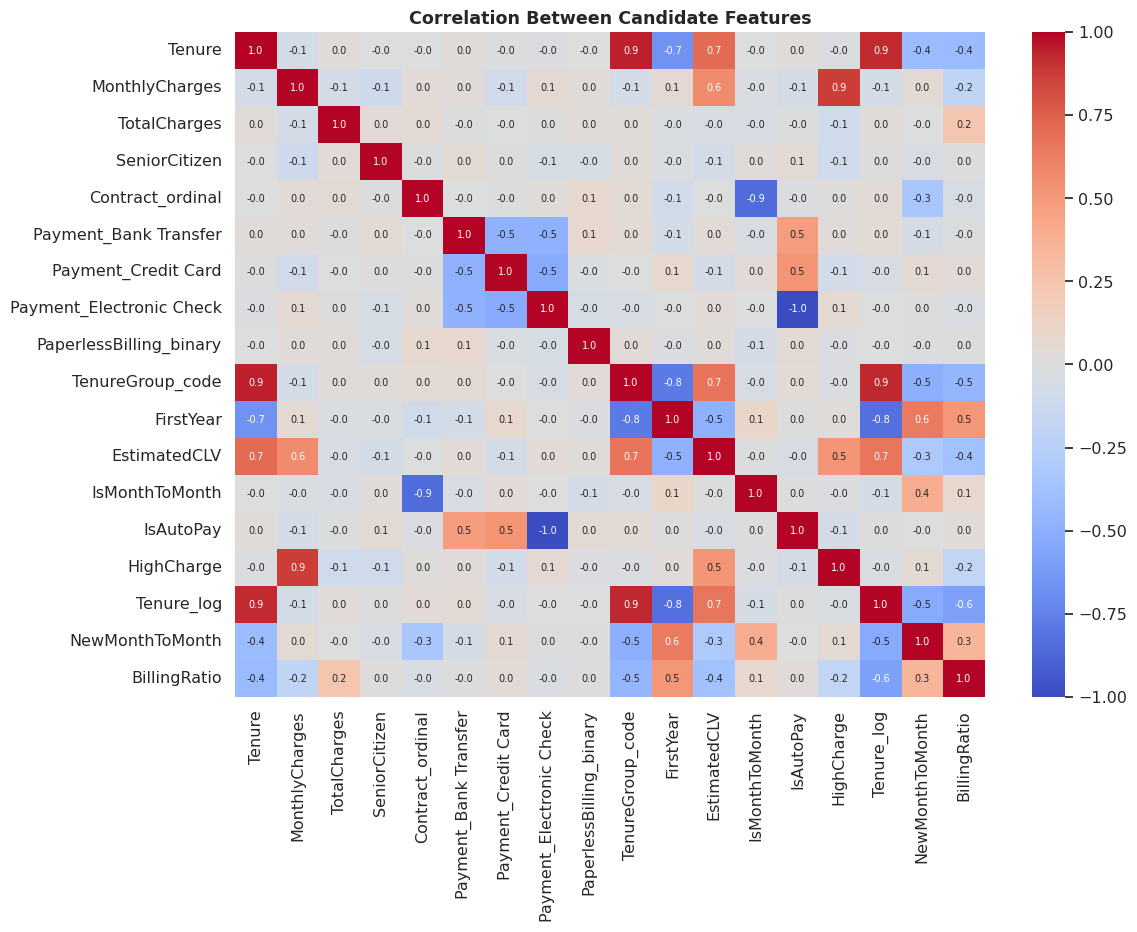

METHOD 1: PAIRS OF FEATURES WITH CORRELATION ABOVE 0.85
  Payment_Electronic Check  <->  IsAutoPay: 1.0
  Tenure  <->  TenureGroup_code: 0.95
  TenureGroup_code  <->  Tenure_log: 0.94
  Tenure  <->  Tenure_log: 0.92
  MonthlyCharges  <->  HighCharge: 0.87
  Contract_ordinal  <->  IsMonthToMonth: 0.86
Two features that say the same thing add no new information, so we keep only one of each pair.
(IsAutoPay is exactly the opposite of Payment_Electronic Check, which is why their correlation is 1.0.)

METHODS 2-4: F-TEST, MUTUAL INFORMATION AND RANDOM FOREST IMPORTANCE
                          F-test p-value  Mutual information  Forest importance  Average rank
Tenure_log                        0.0000              0.2433             0.1905        2.3333
Tenure                            0.0000              0.2364             0.2301        2.6667
TenureGroup_code                  0.0000              0.2240             0.1931        3.0000
FirstYear                         0.0000             

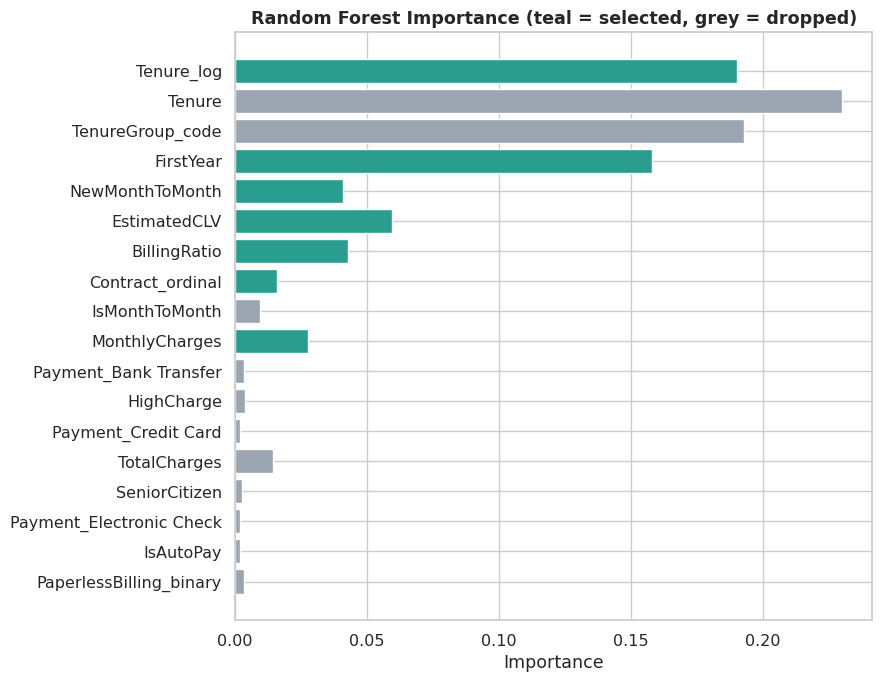

In [ ]:
# Part 4: Feature selection (Day 6) - correlation analysis and importance methods

from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

candidates = ['Tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Contract_ordinal',
              'Payment_Bank Transfer', 'Payment_Credit Card', 'Payment_Electronic Check',
              'PaperlessBilling_binary'] + new_features
tenure_based = ['Tenure', 'TenureGroup_code', 'FirstYear', 'Tenure_log', 'EstimatedCLV',
                'NewMonthToMonth', 'BillingRatio']

# Selection uses the TRAINING customers only (the test customers stay untouched)
sel_train = fe.loc[train_df.index]
X_sel = sel_train[candidates]
y_sel = sel_train['Churn']
print("Candidate features:", len(candidates), "| training customers used:", len(X_sel))

# =====================================================================
# METHOD 1: CORRELATION ANALYSIS - find features that say the same thing
# =====================================================================
corr_matrix = X_sel.corr()
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 7}, ax=ax)
ax.set_title('Correlation Between Candidate Features', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/5_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

high_pairs = []
for i, a in enumerate(candidates):
    for b in candidates[i + 1:]:
        r = abs(corr_matrix.loc[a, b])
        if r > 0.85:
            high_pairs.append((a, b, round(float(r), 2)))
high_pairs.sort(key=lambda p: -p[2])
print("=" * 60)
print("METHOD 1: PAIRS OF FEATURES WITH CORRELATION ABOVE 0.85")
print("=" * 60)
for a, b, r in high_pairs:
    print(f"  {a}  <->  {b}: {r}")
print("Two features that say the same thing add no new information, so we keep only one of each pair.")
print("(IsAutoPay is exactly the opposite of Payment_Electronic Check, which is why their correlation is 1.0.)")

# =====================================================================
# METHODS 2, 3 and 4: HOW MUCH DOES EACH FEATURE HELP TO PREDICT CHURN?
# =====================================================================
f_scores, p_values = f_classif(X_sel, y_sel)                               # statistical test
mutual_info = mutual_info_classif(X_sel, y_sel, random_state=42)           # any kind of link
forest = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced')
forest.fit(X_sel, y_sel)                                                   # model-based importance

scores = pd.DataFrame({'F-test p-value': p_values, 'Mutual information': mutual_info,
                       'Forest importance': forest.feature_importances_}, index=candidates)
scores['Average rank'] = (scores['F-test p-value'].rank(ascending=True) +
                          scores['Mutual information'].rank(ascending=False) +
                          scores['Forest importance'].rank(ascending=False)) / 3
scores = scores.sort_values('Average rank')

print()
print("=" * 60)
print("METHODS 2-4: F-TEST, MUTUAL INFORMATION AND RANDOM FOREST IMPORTANCE")
print("=" * 60)
print(scores.round(4).to_string())
print("Lower p-value, higher mutual information and higher forest importance all mean a stronger link.")

# =====================================================================
# SELECTION RULES
# =====================================================================
rank = scores['Average rank']
alive = list(candidates)
dropped_redundant = []
for a, b, r in high_pairs:
    if a in alive and b in alive:
        loser = a if rank[a] > rank[b] else b
        winner = b if loser == a else a
        alive.remove(loser)
        dropped_redundant.append((loser, winner))

dropped_useless = []
for f in list(alive):
    no_link = scores.loc[f, 'F-test p-value'] > 0.05 and scores.loc[f, 'Forest importance'] < 0.02
    if no_link:
        alive.remove(f)
        dropped_useless.append(f)

selected = [f for f in scores.index if f in alive]
signup_only = [f for f in selected if f not in tenure_based]

print()
print("=" * 60)
print("SELECTION RESULT")
print("=" * 60)
print("Dropped because another feature says the same thing:")
for loser, winner in dropped_redundant:
    print(f"  {loser}  (kept {winner})")
print("Dropped because the F-test finds no clear link (p above 0.05) and the forest gives it little weight:")
for f in dropped_useless:
    print(f"  {f}")
print()
print(f"SELECTED FEATURES ({len(selected)}):", selected)
print(f"SIGN-UP-ONLY FEATURES ({len(signup_only)}, no Tenure-based information):", signup_only)
print()
print("Two feature sets are kept because Tenure may reveal the answer (see the warning in Part 3).")
print("Part 5 builds the pipeline with both sets and compares them.")

colors = [TEAL if f in selected else GREY for f in scores.index[::-1]]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(scores.index[::-1], scores['Forest importance'][::-1], color=colors)
ax.set_title('Random Forest Importance (teal = selected, grey = dropped)', fontweight='bold')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('figures/6_feature_selection.png', dpi=150, bbox_inches='tight')
plt.show()

THE PIPELINE
Raw columns -> 1. build features -> 2. cap outliers (IQR) -> 3. scale (Standard) -> 4. model
Encoding is part of step 1 (ordinal for Contract, binary for PaperlessBilling and the flags).
Every step learns only from the TRAINING customers, then is applied to any new customer.
Feature set A (selected):     ['Tenure_log', 'FirstYear', 'NewMonthToMonth', 'EstimatedCLV', 'BillingRatio', 'Contract_ordinal', 'MonthlyCharges']
Feature set B (sign-up only): ['Contract_ordinal', 'MonthlyCharges']

RESULTS (the test set has 100 customers, 11 of whom left)
                                     Setup  CV ROC-AUC  Test ROC-AUC  Precision  Recall    F1
  Baseline: raw numbers only (no pipeline)       0.970         0.965      0.550   1.000 0.710
    Set A (selected) + Logistic Regression       0.994         0.998      0.647   1.000 0.786
          Set A (selected) + Random Forest       0.994         0.997      1.000   0.727 0.842
Set B (sign-up only) + Logistic Regression       0.707      

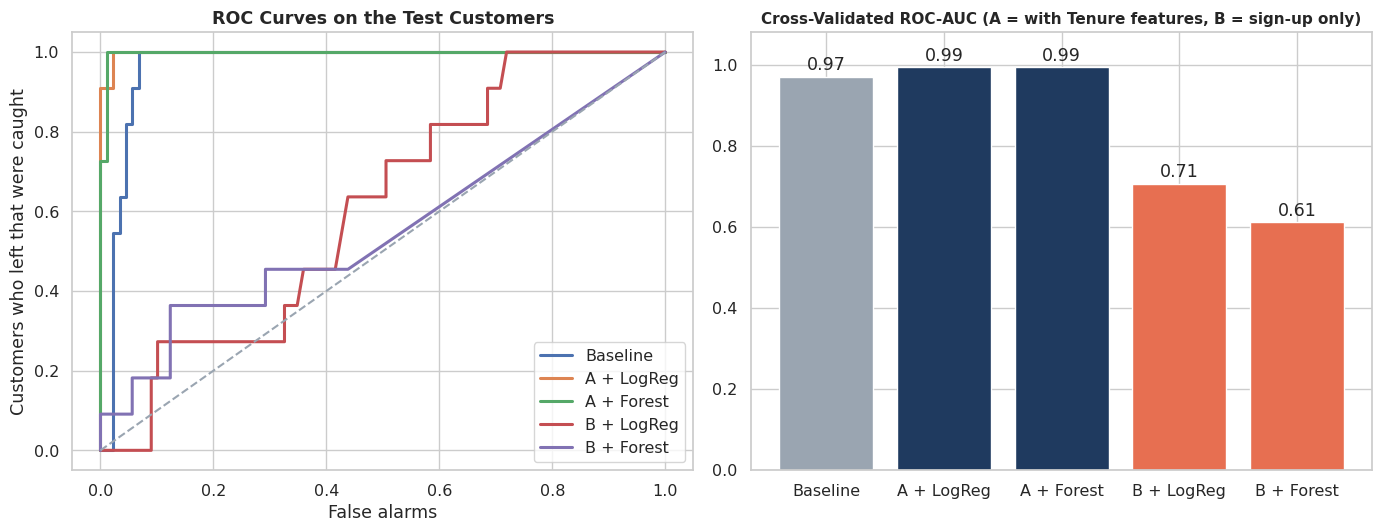

END-TO-END TESTS
Test 1: predict from raw columns only -> [0.007 0.031 0.002] (3 probabilities, no manual steps)
Test 2: processed data has 7 columns, missing values: 0
Test 3: refitting gives identical predictions -> True
Test 4: three new customers
 Tenure  MonthlyCharges       Contract Chance of leaving
      3             150 Month-to-month             99.7%
     60              80       Two year              0.2%
      8              60       One year             61.5%
Test 5: extreme MonthlyCharges of 5000 -> [0.97] (runs without error)

All tests completed.


In [ ]:
# Part 5: Build the complete preprocessing pipeline (Day 7) and test it end to end

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

RAW_COLS = ['Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']
CONTRACT_ORDER = {'Month-to-month': 0, 'One year': 1, 'Two year': 2}
CONTINUOUS = ['Tenure', 'MonthlyCharges', 'TotalCharges', 'EstimatedCLV', 'Tenure_log', 'BillingRatio',
              'TenureGroup_code', 'Contract_ordinal']


# ---------- Step 1: a transformer that builds every feature from the RAW columns ----------
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.median_charge_ = X['MonthlyCharges'].median()          # learned from training data only
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)
        out['Tenure'] = X['Tenure']
        out['MonthlyCharges'] = X['MonthlyCharges']
        out['TotalCharges'] = X['TotalCharges']
        out['SeniorCitizen'] = X['SeniorCitizen']
        out['Contract_ordinal'] = X['Contract'].map(CONTRACT_ORDER)
        out['PaperlessBilling_binary'] = (X['PaperlessBilling'] == 'Yes').astype(int)
        out['TenureGroup_code'] = pd.cut(X['Tenure'], bins=[-np.inf, 11, 23, 47, np.inf], labels=[0, 1, 2, 3]).astype(int)
        out['FirstYear'] = (X['Tenure'] <= 11).astype(int)
        out['EstimatedCLV'] = X['Tenure'] * X['MonthlyCharges']
        out['IsMonthToMonth'] = (X['Contract'] == 'Month-to-month').astype(int)
        out['IsAutoPay'] = X['PaymentMethod'].isin(['Credit Card', 'Bank Transfer']).astype(int)
        out['HighCharge'] = (X['MonthlyCharges'] > self.median_charge_).astype(int)
        out['Tenure_log'] = np.log1p(X['Tenure'])
        out['NewMonthToMonth'] = out['IsMonthToMonth'] * out['FirstYear']
        out['BillingRatio'] = X['TotalCharges'] / out['EstimatedCLV']
        return out


# ---------- Step 2: a transformer that caps outliers with the IQR rule ----------
class IQRCapper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, 25, axis=0), np.percentile(X, 75, axis=0)
        self.low_, self.high_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)   # limits learned from training data
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


# ---------- Step 3: put everything together ----------
def make_churn_pipeline(feature_list, model):
    continuous = [c for c in feature_list if c in CONTINUOUS]
    flags = [c for c in feature_list if c not in CONTINUOUS]
    prepare = ColumnTransformer([
        ('numbers', Pipeline([('cap_outliers', IQRCapper()), ('scale', StandardScaler())]), continuous),
        ('flags', 'passthrough', flags)])
    return Pipeline([('build_features', FeatureBuilder()),
                     ('prepare', prepare),
                     ('model', model)])


print("=" * 60)
print("THE PIPELINE")
print("=" * 60)
print("Raw columns -> 1. build features -> 2. cap outliers (IQR) -> 3. scale (Standard) -> 4. model")
print("Encoding is part of step 1 (ordinal for Contract, binary for PaperlessBilling and the flags).")
print("Every step learns only from the TRAINING customers, then is applied to any new customer.")
print("Feature set A (selected):    ", selected)
print("Feature set B (sign-up only):", signup_only)

X_train_raw, y_train_c = train_df[RAW_COLS], train_df['Churn']
X_test_raw, y_test_c = test_df[RAW_COLS], test_df['Churn']
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

setups = {
    'Baseline: raw numbers only (no pipeline)': Pipeline([
        ('prep', ColumnTransformer([('n', StandardScaler(), ['Tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen'])])),
        ('model', LogisticRegression(class_weight='balanced', max_iter=1000))]),
    'Set A (selected) + Logistic Regression': make_churn_pipeline(selected, LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Set A (selected) + Random Forest': make_churn_pipeline(selected, RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)),
    'Set B (sign-up only) + Logistic Regression': make_churn_pipeline(signup_only, LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Set B (sign-up only) + Random Forest': make_churn_pipeline(signup_only, RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)),
}

rows, test_probs = [], {}
for name, pipe in setups.items():
    cv_auc = cross_val_score(pipe, X_train_raw, y_train_c, cv=cv5, scoring='roc_auc').mean()   # whole pipeline inside the folds
    pipe.fit(X_train_raw, y_train_c)
    prob = pipe.predict_proba(X_test_raw)[:, 1]
    pred = (prob >= 0.5).astype(int)
    test_probs[name] = prob
    rows.append({'Setup': name, 'CV ROC-AUC': cv_auc, 'Test ROC-AUC': roc_auc_score(y_test_c, prob),
                 'Precision': precision_score(y_test_c, pred, zero_division=0),
                 'Recall': recall_score(y_test_c, pred), 'F1': f1_score(y_test_c, pred)})
results = pd.DataFrame(rows)

print()
print("=" * 60)
print("RESULTS (the test set has 100 customers, 11 of whom left)")
print("=" * 60)
print(results.round(3).to_string(index=False))
print()
print("HOW TO READ THIS (ROC-AUC: 0.5 = guessing, 1.0 = perfect):")
print("  - Set A uses Tenure-based features. A very high score here is suspicious, because Tenure may reveal the answer.")
print("  - Set B uses only information known when a customer signs up. This is the fair estimate for predicting new customers.")
print("  - Only 11 customers left in the test set, so test scores can move a lot; the cross-validation score is steadier.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
labels = ['Baseline', 'A + LogReg', 'A + Forest', 'B + LogReg', 'B + Forest']
for label, prob in zip(labels, test_probs.values()):
    fpr, tpr, _ = roc_curve(y_test_c, prob)
    axes[0].plot(fpr, tpr, linewidth=2.2, label=label)
axes[0].plot([0, 1], [0, 1], color=GREY, linestyle='--')
axes[0].set_title('ROC Curves on the Test Customers', fontweight='bold')
axes[0].set_xlabel('False alarms')
axes[0].set_ylabel('Customers who left that were caught')
axes[0].legend(loc='lower right')
axes[1].bar(labels, results['CV ROC-AUC'], color=[GREY, NAVY, NAVY, ORANGE, ORANGE])
axes[1].set_ylim(0, 1.08)
axes[1].set_title('Cross-Validated ROC-AUC (A = with Tenure features, B = sign-up only)', fontweight='bold', fontsize=11)
for i, v in enumerate(results['CV ROC-AUC']):
    axes[1].annotate(f"{v:.2f}", (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.savefig('figures/7_pipeline_results.png', dpi=150, bbox_inches='tight')
plt.show()

# =====================================================================
# END-TO-END TESTS
# =====================================================================
print("=" * 60)
print("END-TO-END TESTS")
print("=" * 60)
final_pipeline = setups['Set A (selected) + Logistic Regression']

# Test 1: the pipeline accepts RAW data and nothing else is needed
raw_batch = X_test_raw.head(3)
print("Test 1: predict from raw columns only ->", final_pipeline.predict_proba(raw_batch)[:, 1].round(3), "(3 probabilities, no manual steps)")

# Test 2: the processed data has no missing values and the right number of columns
processed = final_pipeline[:-1].transform(X_test_raw)
print(f"Test 2: processed data has {processed.shape[1]} columns, missing values: {int(np.isnan(processed).sum())}")

# Test 3: same result when the pipeline is rebuilt and refitted (reproducible)
again = make_churn_pipeline(selected, LogisticRegression(class_weight='balanced', max_iter=1000)).fit(X_train_raw, y_train_c)
same = np.allclose(again.predict_proba(X_test_raw)[:, 1], final_pipeline.predict_proba(X_test_raw)[:, 1])
print("Test 3: refitting gives identical predictions ->", same)

# Test 4: new customers described in plain raw columns
new_customers = pd.DataFrame([
    {'Tenure': 3, 'MonthlyCharges': 150, 'TotalCharges': 450, 'Contract': 'Month-to-month', 'PaymentMethod': 'Electronic Check', 'PaperlessBilling': 'Yes', 'SeniorCitizen': 0},
    {'Tenure': 60, 'MonthlyCharges': 80, 'TotalCharges': 4800, 'Contract': 'Two year', 'PaymentMethod': 'Bank Transfer', 'PaperlessBilling': 'No', 'SeniorCitizen': 1},
    {'Tenure': 8, 'MonthlyCharges': 60, 'TotalCharges': 480, 'Contract': 'One year', 'PaymentMethod': 'Credit Card', 'PaperlessBilling': 'Yes', 'SeniorCitizen': 0}])
new_customers['Chance of leaving'] = (final_pipeline.predict_proba(new_customers[RAW_COLS])[:, 1] * 100).round(1).astype(str) + '%'
print("Test 4: three new customers")
print(new_customers[['Tenure', 'MonthlyCharges', 'Contract', 'Chance of leaving']].to_string(index=False))

# Test 5: an extreme value does not break the pipeline (the capper limits it)
extreme = new_customers[RAW_COLS].head(1).copy()
extreme['MonthlyCharges'] = 5000
extreme['TotalCharges'] = 15000
print("Test 5: extreme MonthlyCharges of 5000 ->", final_pipeline.predict_proba(extreme)[:, 1].round(3), "(runs without error)")

print()
print("All tests completed.")